[![preview notebook](https://img.shields.io/static/v1?label=render%20on&logo=github&color=87ce3e&message=GitHub)](https://github.com/open-atmos/PySDM/blob/main/examples/PySDM_examples/sandbox/Mazur_2027_MSc/sampling_explanation.ipynb)
[![launch on mybinder.org](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/open-atmos/PySDM.git/main?urlpath=lab/tree/examples/PySDM_examples/sandbox/Mazur_2027_MSc/sampling_explanation.ipynb)
[![launch on Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/open-atmos/PySDM/blob/main/examples/PySDM_examples/sandbox/Mazur_2027_MSc/sampling_explanation.ipynb)

This notebook illustrates how particle attributes are sampled in the singular and time-dependent immersion freezing models and compares the resulting distributions.

In [1]:
import os, sys

import particulator
from PySDM_examples.featured.Arabas_et_al_2025 import make_freezing_spec_plot
from dynamics import Coalescence
from products.freezing import cooling_rate

os.environ['NUMBA_THREADING_LAYER'] = 'workqueue'  # PySDM & PyMPDATA don't work with TBB; OpenMP has extra dependencies on macOS
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PySDM-examples', 'PySDM')

In [2]:
import numpy as np
from PySDM_examples.sandbox.Abade_and_Albuquerque_2024.sampling import sampling, sampling_new
from PySDM_examples.sandbox.Abade_and_Albuquerque_2024.help_funcs import run_simulation, make_particulator_case, rmse_between_curves
from PySDM import Formulae
from PySDM.physics import si
from PySDM_examples.featured.Arabas_et_al_2025.commons import FREEZING_CONSTANTS
from matplotlib import pyplot as plt
from PySDM.initialisation.spectra import Lognormal
from PySDM import Particulator
from PySDM.environments import Box
from PySDM.backends import Numba
from PySDM.dynamics import Freezing

In [3]:
attributessing_old={}
attributestdep_old={}
formulae=Formulae(
    constants={
            **FREEZING_CONSTANTS["dust"],
        },
    freezing_temperature_spectrum="Niemand_et_al_2012",
    particle_shape_and_density="MixedPhaseSpheres",
)
rng=np.random.default_rng(seed=444)

sampling(n_sd=1000, freezing_inp_frac=0.5,rng=rng,attributes=attributessing_old, formulae=formulae, singular=True, freezing_inp_dry_radius=10.0*si.um)
sampling(n_sd=1000, freezing_inp_frac=0.5,rng=rng,attributes=attributestdep_old, formulae=formulae, singular=False, freezing_inp_dry_radius=10.0*si.um)

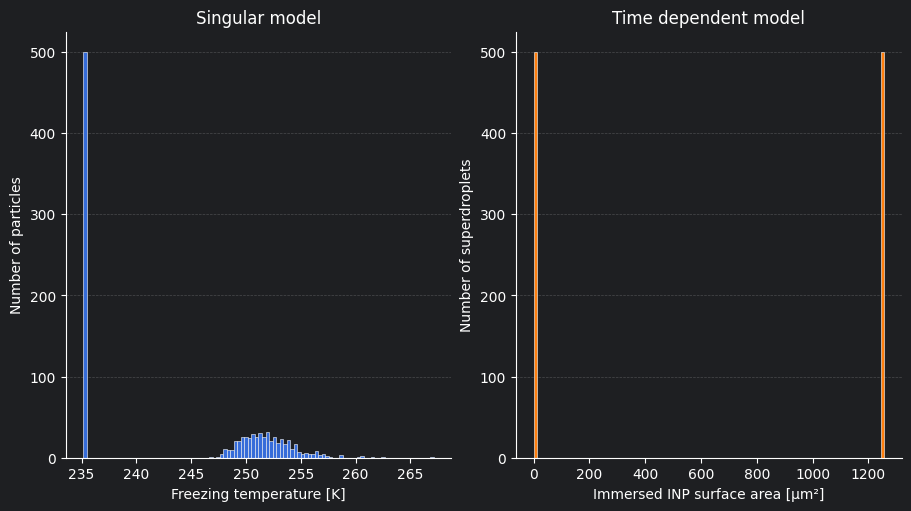

In [4]:
fig, ax = plt.subplots(1,2, figsize = (9,5), constrained_layout=True,)
ax[0].hist(attributessing_old["freezing temperature"], bins=100, linewidth=0.4, edgecolor="white")
ax[0].set(xlabel="Freezing temperature [K]", ylabel="Number of particles")
ax[0].grid(axis="y", linestyle="--", alpha=0.3)
ax[0].set_axisbelow(True)
ax[0].spines[["top", "right"]].set_visible(False)
ax[0].set(title="Singular model")

ax[1].hist(
    attributestdep_old["immersed surface area"] / si.um**2, bins=100, linewidth=0.4, edgecolor="white", color="tab:orange",
)
ax[1].set(xlabel="Immersed INP surface area [µm²]", ylabel="Number of superdroplets")
ax[1].grid(axis="y", linestyle="--", alpha=0.3)
ax[1].set_axisbelow(True)
ax[1].spines[["top", "right"]].set_visible(False)
ax[1].set(title="Time dependent model")
plt.show()

In [5]:
attributessing_new={}
attributestdep_new={}

A_sing=sampling_new(n_sd=1000, freezing_inp_frac=0.5,rng=rng,attributes=attributessing_new, formulae=formulae, singular=True, freezing_inp_dry_radius=10.0*si.um, inp_surface_sigma=2.5)
A_t=sampling_new(n_sd=1000, freezing_inp_frac=0.5,rng=rng,attributes=attributestdep_new, formulae=formulae, singular=False, freezing_inp_dry_radius=10.0*si.um, inp_surface_sigma=2.5)

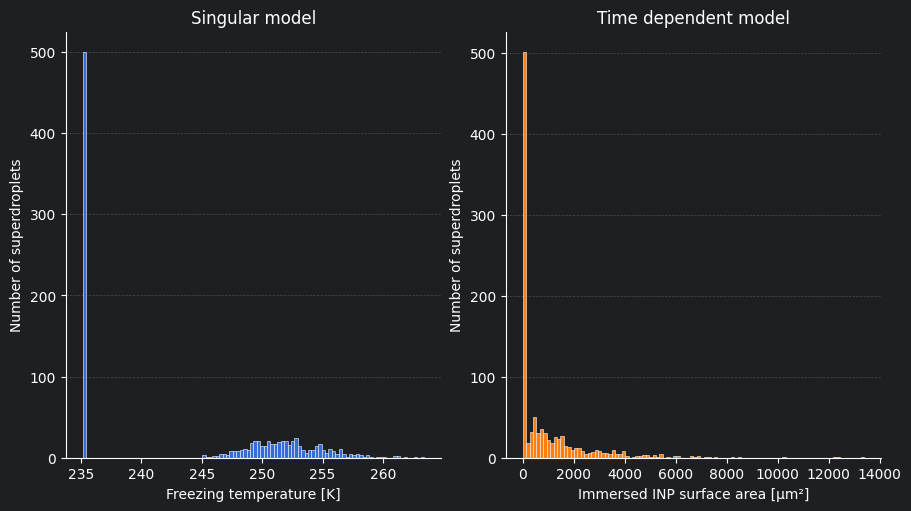

In [6]:
fig, ax = plt.subplots(1,2, figsize = (9,5), constrained_layout=True,)
ax[0].hist(attributessing_new["freezing temperature"], bins=100, linewidth=0.4, edgecolor="white")
ax[0].set(xlabel="Freezing temperature [K]", ylabel="Number of superdroplets")
ax[0].grid(axis="y", linestyle="--", alpha=0.3)
ax[0].set_axisbelow(True)
ax[0].spines[["top", "right"]].set_visible(False)
ax[0].set(title="Singular model")

ax[1].hist(
    attributestdep_new["immersed surface area"] / si.um**2, bins=100, linewidth=0.4, edgecolor="white", color="tab:orange",
)
ax[1].set(xlabel="Immersed INP surface area [µm²]", ylabel="Number of superdroplets")
ax[1].grid(axis="y", linestyle="--", alpha=0.3)
ax[1].set_axisbelow(True)
ax[1].spines[["top", "right"]].set_visible(False)
ax[1].set(title="Time dependent model")
plt.show()

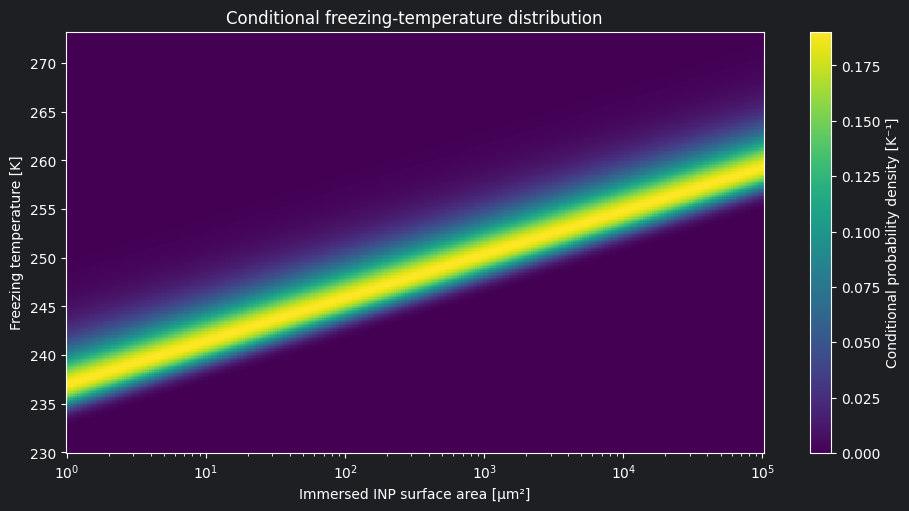

In [7]:
temperature = np.linspace(230, 273.15, 300) * si.K
area = np.geomspace(1, 1e5, 300) * si.um**2
A, T = np.meshgrid(area, temperature)

pdf = formulae.freezing_temperature_spectrum.pdf(
    T=T,
    A_insol=A,
)
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
plot = ax.pcolormesh(
    area / si.um**2,
    temperature / si.K,
    pdf * si.K,
    shading="auto",
    cmap="viridis",
)
ax.set(
    xscale="log",
    xlabel="Immersed INP surface area [µm²]",
    ylabel="Freezing temperature [K]",
    title="Conditional freezing-temperature distribution",
)
fig.colorbar(plot, ax=ax, label="Conditional probability density [K⁻¹]")
plt.show()

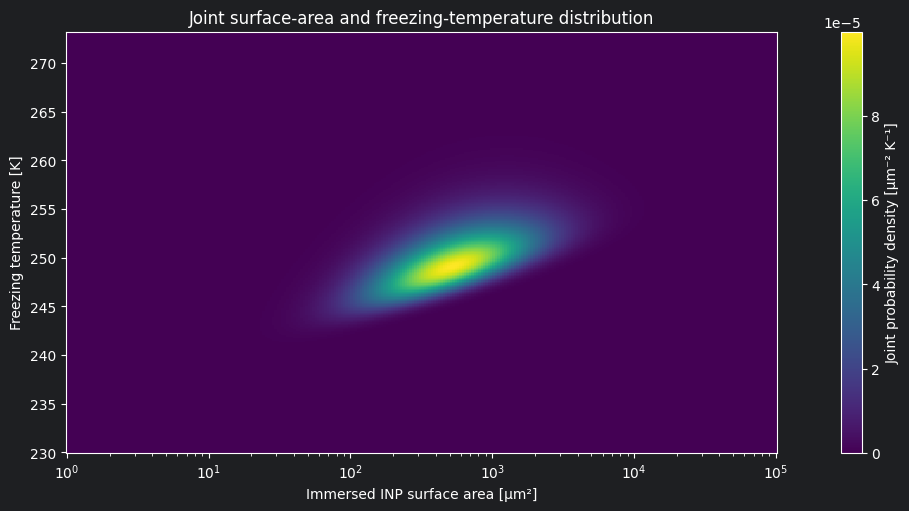

In [8]:
surface_median = formulae.trivia.sphere_surface(
    diameter=2 * 10.0*si.um
)
surface_spectrum = Lognormal(
    norm_factor=1,
    m_mode=surface_median,
    s_geom=2.55,
)
joint_pdf = pdf * surface_spectrum.pdf(A)

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
plot = ax.pcolormesh(
    area / si.um**2,
    temperature / si.K,
    joint_pdf * si.um**2 * si.K,
    shading="auto",
    cmap="viridis",
)
ax.set(
    xscale="log",
    xlabel="Immersed INP surface area [µm²]",
    ylabel="Freezing temperature [K]",
    title="Joint surface-area and freezing-temperature distribution",
)
fig.colorbar(plot, ax=ax, label="Joint probability density [µm⁻² K⁻¹]")
plt.show()

In [9]:
#n_sd=1000, freezing_inp_frac=0.5,rng=rng,attributes=attributessing_old, formulae=formulae, singular=True, freezing_inp_dry_radius=10.0*si.um
n_sd=len(attributessing_new["freezing temperature"])
dt=1*si.s
dv=1*si.m**3
N=100/si.l
rho= 1000*si.hPa / formulae.constants.Rd / (300*si.K)
backend = Numba(formulae=formulae)
attributessing_new["immersed surface area"] = np.nan_to_num(
    A_sing.copy(),
    nan=0.0,
)
attributessing_new["multiplicity"]=np.full(shape=n_sd,fill_value=N*dv/n_sd*rho/formulae.constants.rho_STP)
attributessing_new["signed water mass"]=np.full(shape=n_sd, fill_value=1*si.ug)

particulator = Particulator(n_sd=n_sd,attributes=attributessing_new,environment=Box(dt=dt, dv=dv, backend=backend),
                            dynamics=(Freezing(immersion_freezing="singular"),))
cooling_rate = 25 *si.K/si.min
T0=273.15*si.K
particulator.environment["RH"]=1.2
#ilos zamarznietych w czasie korzystaj z produktow
# pobaw się kiedy dla jakiego cooling rate zgadza się z singel a ABIFM0


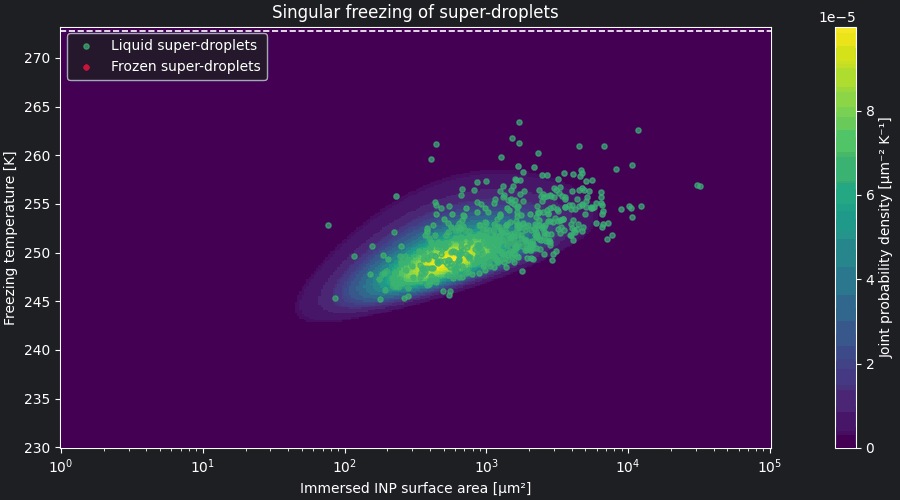

HTML(value="<a href='./tmpe6dc4z2f.gif' target='_blank'>./tmpe6dc4z2f.gif</a><br>")

In [10]:
from help_funcs import make_freezing_frame
from open_atmos_jupyter_utils import show_anim

plot_func = make_freezing_frame(
    particulator,
    area,
    temperature,
    joint_pdf,
    T0,
    cooling_rate,
    singular=True,
)

show_anim(plot_func, range(1,101), duration=0.125, loop=0)



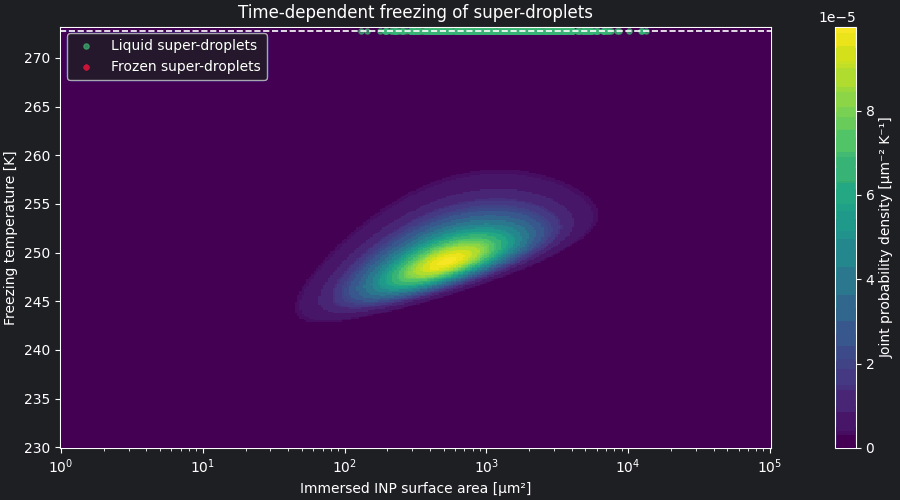

HTML(value="<a href='./tmpgtlwlw8a.gif' target='_blank'>./tmpgtlwlw8a.gif</a><br>")

In [11]:
formulae_tdep = Formulae(
    constants={
        **FREEZING_CONSTANTS["dust"],
    },
    freezing_temperature_spectrum="Niemand_et_al_2012",
    heterogeneous_ice_nucleation_rate="ABIFM",
    particle_shape_and_density="MixedPhaseSpheres",
)

attributestdep_new["multiplicity"]=np.full(shape=n_sd,fill_value=N*dv/n_sd*rho/formulae.constants.rho_STP)
attributestdep_new["signed water mass"]=np.full(shape=n_sd, fill_value=1*si.ug)
backend_tdep = Numba(formulae=formulae_tdep)
env_tdep = Box(dt=dt, dv=dv, backend=backend_tdep)
env_tdep["T"] = T0
env_tdep["RH"] = 1.2
env_tdep["rhod"] = rho

particulator = Particulator(n_sd=n_sd,attributes=attributestdep_new,environment=env_tdep,
                            dynamics=(Freezing(immersion_freezing="time-dependent",),))

plot_func = make_freezing_frame(
    particulator,
    area,
    temperature,
    joint_pdf,
    T0,
    cooling_rate,
    singular=False,
)

show_anim(plot_func, range(1,101), duration=0.125, loop=0)



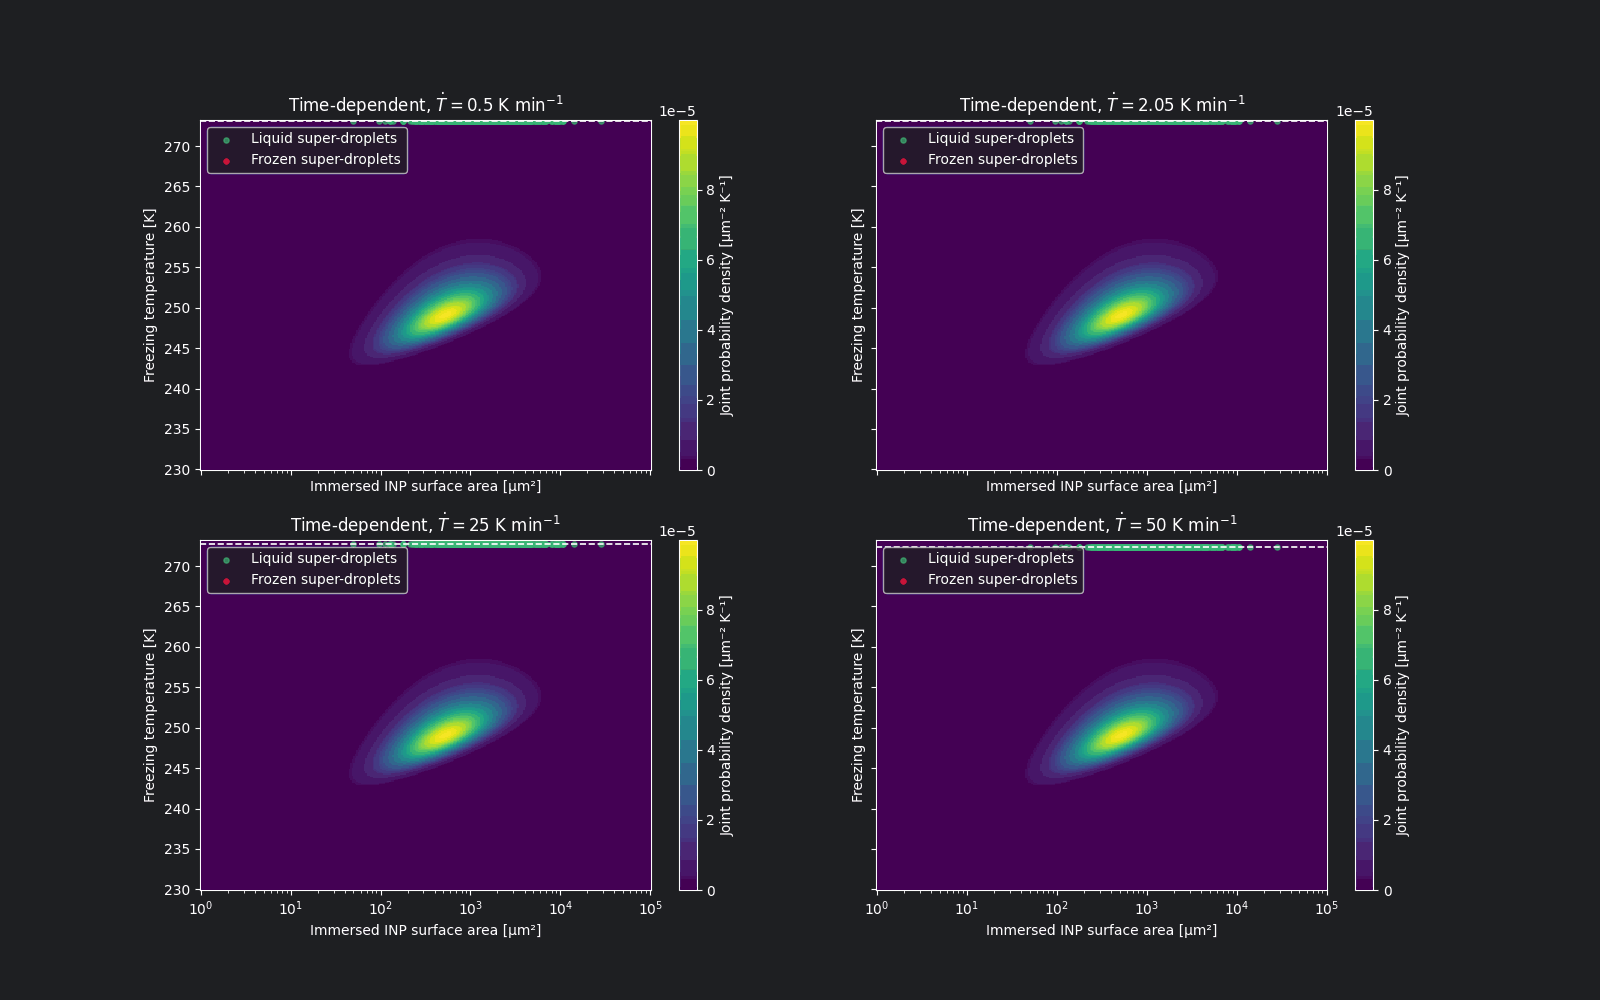

HTML(value="<a href='./tmpbicca3mw.gif' target='_blank'>./tmpbicca3mw.gif</a><br>")

In [12]:
cooling_rates = np.asarray((0.5, 2.05, 25, 50,))*si.K/si.min
n_frames = 50
T_end = 235 *si.K
draw_subplot_help = None
cases = []


for cooling_rate in cooling_rates:
    particulator = make_particulator_case(
        singular=False,
        seed=444,
        T0=T0,
    )

    n_steps = int(np.ceil(
        (T0 - T_end) / (cooling_rate * particulator.dt)
    ))

    frame_steps = np.unique(np.linspace(1, n_steps, n_frames, dtype=int))

    draw_case = make_freezing_frame(
        particulator=particulator,
        area=area,
        temperature=temperature,
        joint_pdf=joint_pdf,
        T0=T0,
        cooling_rate=cooling_rate,
        singular=False,
    )

    cases.append(
        {
            "cooling_rate": cooling_rate,
            "frame_steps": frame_steps,
            "draw": draw_case,
        }
    )

def plot_all_rates(i):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(16, 10),
        sharex=True,
        sharey=True,
    )

    for ax, case in zip(axes.flat, cases):
        last_index = len(case["frame_steps"]) - 1
        step_index = min(i, last_index)
        case["draw"](case["frame_steps"][step_index],ax)

        ax.set_title(
            rf"Time-dependent, "
            rf"$\dot{{T}}={case['cooling_rate'] / (si.K / si.min):g}$ K min$^{{-1}}$"
        )

    return fig

show_anim(
    plot_all_rates,
    range(n_frames),
    duration=0.125,
    loop=0,
)

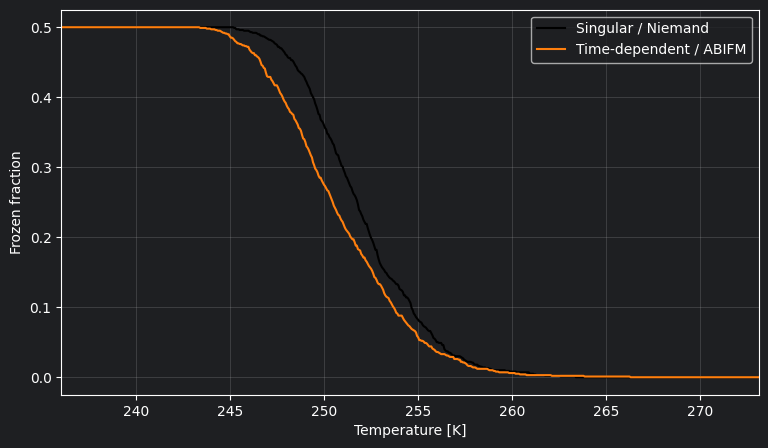

In [10]:
from PySDM import products

output_products = (
    products.Time(name="time"),
    products.AmbientTemperature(name="T"),
    products.IceWaterContent(name="ice water content"),
    products.CloudWaterContent(name="total water content"),
)

cooling_rate = 3.5 * si.K / si.min
T0 = 273.15 * si.K
T_end = 236 * si.K

env_sing = Box(dt=dt, dv=dv, backend=backend)
env_sing["T"] = T0
env_sing["RH"] = 1.2
env_sing["rhod"] = rho
particulator_sing = Particulator(n_sd=n_sd,attributes=attributessing_new,environment=env_sing,
                            dynamics=(Freezing(immersion_freezing="singular",),), products=output_products)
formulae_tdep = Formulae(
    constants={
        **FREEZING_CONSTANTS["dust"],
    },
    freezing_temperature_spectrum="Niemand_et_al_2012",
    heterogeneous_ice_nucleation_rate="ABIFM",
    particle_shape_and_density="MixedPhaseSpheres",
)

attributestdep_new["multiplicity"]=np.full(shape=n_sd,fill_value=N*dv/n_sd*rho/formulae.constants.rho_STP)
attributestdep_new["signed water mass"]=np.full(shape=n_sd, fill_value=1*si.ug)
backend_tdep = Numba(formulae=formulae_tdep)
env_tdep = Box(dt=dt, dv=dv, backend=backend_tdep)
env_tdep["T"] = T0
env_tdep["RH"] = 1.2
env_tdep["rhod"] = rho

particulator_tdep = Particulator(n_sd=n_sd,attributes=attributestdep_new,environment=env_tdep,
                            dynamics=(Freezing(immersion_freezing="time-dependent",),), products=output_products)


T_sing, f_sing, _ = run_simulation(particulator_sing, T0, T_end, cooling_rate)
T_tdep, f_tdep, _ = run_simulation(particulator_tdep, T0, T_end, cooling_rate)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(T_sing, f_sing, label="Singular / Niemand", color="black")
ax.plot(T_tdep, f_tdep, label="Time-dependent / ABIFM", color="tab:orange")
ax.set(
    xlabel="Temperature [K]",
    ylabel="Frozen fraction",
    xlim=(T0 / si.K, T_end / si.K),
)
ax.invert_xaxis()
ax.grid(alpha=0.3)
ax.legend()

Best cooling rate: 2.05 K/min
Best RMSE: 0.0102


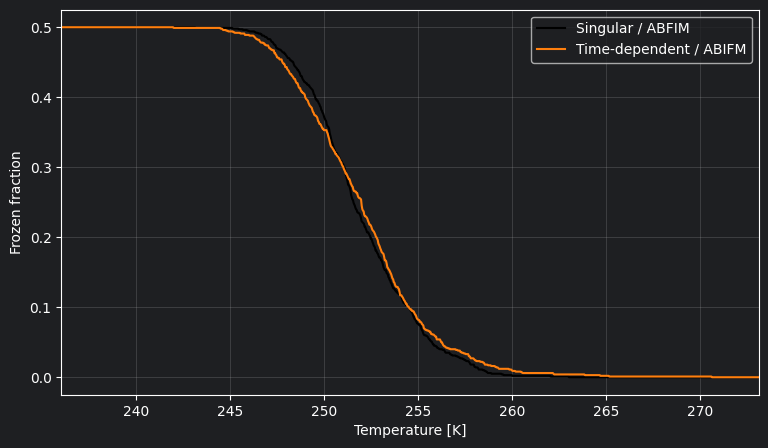

In [11]:
cooling_rates = np.linspace(1.95, 2.05, 10) * si.K / si.min

particulator_sing = make_particulator_case(
    singular=True,
    seed=444,
    T0=T0,
)

T_sing, f_sing, _ = run_simulation(
    particulator_sing,
    T0,
    T_end,
    cooling_rates[0],
)

best_rmse = np.inf
best_rate = None
results = {}

for cooling_rate in cooling_rates:
    particulator_tdep = make_particulator_case(
        singular=False,
        seed=444,
        T0=T0,
    )

    T_tdep, f_tdep, _ = run_simulation(
        particulator_tdep,
        T0,
        T_end,
        cooling_rate,
    )

    rmse = rmse_between_curves(
        T_sing,
        f_sing,
        T_tdep,
        f_tdep,
        Tmin=238,
        Tmax=264,
    )

    results[cooling_rate] = {
        "T": T_tdep,
        "frozen_fraction": f_tdep,
        "rmse": rmse,
    }

    if rmse < best_rmse:
        best_rmse = rmse
        best_rate = cooling_rate
        best_T_tdep = T_tdep
        best_f_tdep = f_tdep

print(
    f"Best cooling rate: {best_rate / (si.K / si.min):.3g} K/min"
)
print(f"Best RMSE: {best_rmse:.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(T_sing, f_sing, label="Singular / ABFIM", color="black")
ax.plot(best_T_tdep, best_f_tdep, label="Time-dependent / ABIFM", color="tab:orange")
ax.set(
    xlabel="Temperature [K]",
    ylabel="Frozen fraction",
    xlim=(T0 / si.K, T_end / si.K),
)
ax.invert_xaxis()
ax.grid(alpha=0.3)
ax.legend()

In [12]:
cooling_rates = np.array([0.75, 1.25, 2.05, 3.5]) * si.K / si.min

particulator_sing = make_particulator_case(
    singular=True,
    seed=444,
    T0=T0,
)

T_sing, f_sing, _ = run_simulation(
    particulator_sing,
    T0,
    T_end,
    cooling_rates[0],
)

results = {}
results_sing = {}
for cooling_rate in cooling_rates:
    particulator_tdep = make_particulator_case(
        singular=False,
        seed=444,
        T0=T0,
    )
    particulator_sing = make_particulator_case(
        singular=True,
        seed=444,
        T0=T0,
    )

    T_tdep, f_tdep, T_event_tdep = run_simulation(
        particulator_tdep,
        T0,
        T_end,
        cooling_rate,
    )

    T_sing, f_sing, T_event_sing = run_simulation(
        particulator_sing,
        T0,
        T_end,
        cooling_rate,
    )

    results[cooling_rate] = {
        "T": T_tdep,
        "frozen_fraction": f_tdep,
        "T_event": T_event_tdep,
    }
    results_sing[cooling_rate] = {
        "T": T_sing,
        "frozen_fraction": f_sing,
        "T_event": T_event_sing,
    }


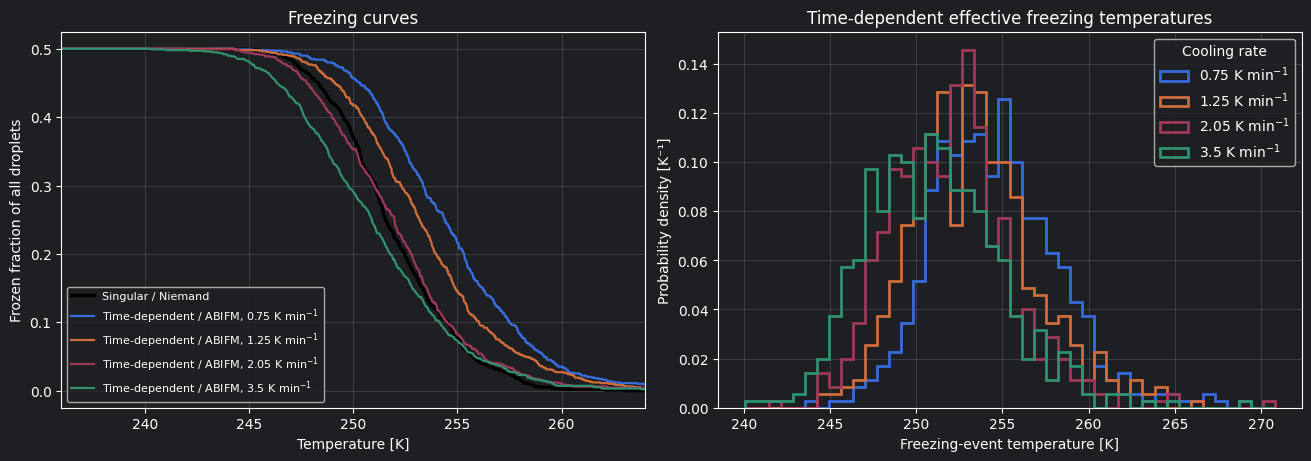

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

ax = axes[0]

ax.plot(
    T_sing,
    f_sing,
    color="black",
    linewidth=2.5,
    label="Singular / Niemand",
)

for cooling_rate, result in results.items():
    rate = cooling_rate / (si.K / si.min)

    ax.plot(
        result["T"],
        result["frozen_fraction"],
        linewidth=1.6,
        label=fr"Time-dependent / ABIFM, ${rate:.3g}$ K min$^{{-1}}$",
    )

ax.set(
    xlim=(236, 264),
    xlabel="Temperature [K]",
    ylabel="Frozen fraction of all droplets",
    title="Freezing curves",
)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

ax = axes[1]

all_event_temperatures = np.concatenate([
    result["T_event"][np.isfinite(result["T_event"])] / si.K
    for result in results.values()
])

bins = np.linspace(
    all_event_temperatures.min() - 0.2,
    all_event_temperatures.max() + 0.2,
    45,
)

for cooling_rate, result in results.items():
    rate = cooling_rate / (si.K / si.min)

    T_event = result["T_event"]
    frozen = np.isfinite(T_event)

    ax.hist(
        T_event[frozen] / si.K,
        bins=bins,
        histtype="step",
        density=True,
        linewidth=2,
        label=fr"${rate:.3g}$ K min$^{{-1}}$",
    )

ax.set(
    xlabel="Freezing-event temperature [K]",
    ylabel="Probability density [K⁻¹]",
    title="Time-dependent effective freezing temperatures",
)
ax.grid(alpha=0.3)
ax.legend(title="Cooling rate")

In [1]:
#co się dzieje jak jest nieliniowy cooling rate po jakiejs funkcji albo w pelni chaotyczny
#czy da się pare rodzajów inp naraz
#usuwanie dodawanie w tracie symulacji INPow
#req_attr(TemperatureOfLastFreezing)
#katalog MazurMScThesii